# Combining Atlas + Flock Camera Data + Immigration Data

Findings - 21,401 mapped cameras (76% flock), 7 rural counties with cameras but no Atlas ALPR record; 463 big box store cameras, 38% in cities were police also use flock and 1612 "immigration" searches, 21 plausibly enforcement related after reading through. 

In [42]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

TABLES = 'data/tables'
atlas = pd.read_csv(f'{TABLES}/ca_surveillance_flat.csv')
cams = pd.read_csv(f'{TABLES}/ca_alpr_cameras_clean.csv')

print(len(atlas), 'Atlas deployments')
print(len(cams), 'mapped cameras')

1085 Atlas deployments
21402 mapped cameras


- One atlas row is an agency using a technology, and one camera row is a single camera on a pole. They describe different things, not really a row to row match. 
- Camera file has no county or city column at all, only cooordinates. Need to work out which county each camera is in.


In [43]:
COUNTY_SRC = 'https://www2.census.gov/geo/tiger/GENZ2023/shp/cb_2023_us_county_500k.zip'

counties = gpd.read_file(COUNTY_SRC)
print(len(counties), 'Counties in the whole US')

counties = counties[counties['STATEFP'] == '06']
print(len(counties), 'Counties in California')

counties[['NAMELSAD', 'ALAND', 'geometry']].head()

3235 Counties in the whole US
58 Counties in California


,NAMELSAD,ALAND,geometry
7,Los Angeles County,10515988121,"MULTIPOLYGON (((-118.60442 33.47855, -118.5987..."
8,Santa Cruz County,1152818089,"POLYGON ((-122.31768 37.18694, -122.28858 37.1..."
9,Sonoma County,4080103614,"POLYGON ((-123.53354 38.76841, -123.52851 38.7..."
10,Contra Costa County,1856752855,"POLYGON ((-122.42976 37.9654, -122.41859 37.96..."
11,Alpine County,1912292607,"POLYGON ((-120.07239 38.70277, -120.06762 38.7..."


In [44]:
# tidy county table 
counties = counties[['NAMELSAD', 'ALAND', 'geometry']]
counties = counties.rename(columns={'NAMELSAD': 'county_name'})

counties = counties.to_crs('EPSG:3310')

counties['land_sq_mi'] = (counties['ALAND'] / 2_589_988).round(1)

counties[['county_name', 'land_sq_mi']].sort_values('land_sq_mi', ascending=False).head()


,county_name,land_sq_mi
812,San Bernardino County,20068.2
860,Inyo County,10197.3
1845,Kern County,8134.7
337,Riverside County,7209.3
1126,Siskiyou County,6278.8


In [45]:
# city/town boundaries 
PLACE_SRC = 'https://www2.census.gov/geo/tiger/GENZ2023/shp/cb_2023_06_place_500k.zip'

places = gpd.read_file(PLACE_SRC)
places = places[['NAME', 'geometry']]
places = places.rename(columns={'NAME': 'city'})
places = places.to_crs('EPSG:3310')

print(len(places), 'cities and towns in California')
places.head

#1,618 places, geometry numbers are in meters, same as the counties. 

1618 cities and towns in California


<bound method NDFrame.head of                             city  \
0                       Richmond   
1                           Napa   
2                       Palmdale   
3     San Buenaventura (Ventura)   
4                     Loma Linda   
...                          ...   
1613                     Potrero   
1614               Oroville East   
1615                      Monson   
1616                 Green Acres   
1617                  Campo Seco   

                                               geometry  
0     MULTIPOLYGON (((-207649.878 -3451.802, -207469...  
1     MULTIPOLYGON (((-194635.317 25553.507, -194282...  
2     POLYGON ((157014.188 -380239.312, 157011.852 -...  
3     MULTIPOLYGON (((64665.952 -407687.269, 64733.9...  
4     MULTIPOLYGON (((253743.831 -434063.725, 253803...  
...                                                 ...  
1613  POLYGON ((317086.057 -594394.95, 317461.564 -5...  
1614  MULTIPOLYGON (((-131133.798 168791.202, -13106...  
1615  POLYGON (

In [46]:

# city/town boundaries
PLACE_SRC = 'https://www2.census.gov/geo/tiger/GENZ2023/shp/cb_2023_06_place_500k.zip'

places = gpd.read_file(PLACE_SRC)
places = places[['NAME', 'geometry']]
places = places.rename(columns={'NAME': 'city'})
places = places.to_crs('EPSG:3310')
# crs='EPSG:4326' to_crs, first you tell geopandas what the numbers are (degrees), then 
# convert to what you want (meters). 
print(len(places), 'cities and towns in California')
places.head()


1618 cities and towns in California


,city,geometry
0,Richmond,"MULTIPOLYGON (((-207649.878 -3451.802, -207469..."
1,Napa,"MULTIPOLYGON (((-194635.317 25553.507, -194282..."
2,Palmdale,"POLYGON ((157014.188 -380239.312, 157011.852 -..."
3,San Buenaventura (Ventura),"MULTIPOLYGON (((64665.952 -407687.269, 64733.9..."
4,Loma Linda,"MULTIPOLYGON (((253743.831 -434063.725, 253803..."


In [47]:
# camera into point on map 
# cams is a normal table with the lat and lon columns, geo pandas needs point for 
# each camera so it can check which county shape the point falls inside of. 
# city/town boundaries
pts = gpd.GeoDataFrame(
    cams,
    geometry=gpd.points_from_xy(cams['lon'], cams['lat']),
    crs='EPSG:4326'
)
pts = pts.to_crs('EPSG:3310')

print(len(pts), 'camera points')
pts[['osm_id', 'lat', 'lon', 'geometry']].head()

21402 camera points


,osm_id,lat,lon,geometry
0,33219729,37.617970,-122.152597,POINT (-189726.318 -42134.427)
1,53092228,37.823138,-122.217199,POINT (-194885.879 -19201.687)
2,53119037,37.832287,-122.227101,POINT (-195732.231 -18164.582)
3,57798203,37.932431,-122.403333,POINT (-210935.238 -6657.275)
4,58343898,40.411194,-120.755364,POINT (-64108.475 266385.5)


All 21, 402 cameras are now points in meters/latitude 40.4 is up north, and its y-value (266,385) is positive, while the Bay Area rows near latitude 37.8 have negative y-values. North = bigger y. The grid makes sense.

# Each camera gets a county and city

In [48]:
#spatial join, which county is each camera inside
pts = gpd.sjoin(pts, counties[['county_name', 'geometry']],
                how='left', predicate='within')
pts = pts.drop(columns='index_right')

print(pts['county_name'].notna().sum(), 'cameras got a county')
print(pts['county_name'].isna().sum(), 'cameras did NOT get a county')
pts[['osm_id', 'lat', 'lon', 'county_name']].head()

21376 cameras got a county
26 cameras did NOT get a county


,osm_id,lat,lon,county_name
0,33219729,37.617970,-122.152597,NaN
1,53092228,37.823138,-122.217199,Alameda County
2,53119037,37.832287,-122.227101,Alameda County
3,57798203,37.932431,-122.403333,Contra Costa County
4,58343898,40.411194,-120.755364,Lassen County


In [49]:
#spatial join part 2 - nearest county for 26 left overs
# the 26 leftovers (bridges, coastline): give NEAREST county 
miss = pts['county_name'].isna()

near = gpd.sjoin_nearest(pts.loc[miss].drop(columns='county_name'),
                         counties[['county_name', 'geometry']], how='left')
near = near[~near.index.duplicated()]

pts.loc[miss, 'county_name'] = near['county_name'].values

print(pts['county_name'].isna().sum(), 'cameras still missing a county')
pts.loc[miss, ['osm_id', 'lat', 'lon', 'county_name']].head(10)

0 cameras still missing a county


,osm_id,lat,lon,county_name
0,33219729,37.617970,-122.152597,Alameda County
137,6365077237,37.618242,-122.152644,Alameda County
138,6365077238,37.618147,-122.152621,Alameda County
148,6975177785,37.618619,-122.150931,Alameda County
458,12269476896,37.787039,-122.387403,San Francisco County
2070,12503144112,33.674781,-118.026520,Orange County
2078,12503823266,33.671729,-118.022540,Orange County
7734,13288015899,33.742256,-118.114096,Orange County
9791,13403924602,33.021149,-117.284336,San Diego County
9792,13403931501,33.021412,-117.284338,San Diego County


In [50]:
# give each camera a city 
# spatial join: which city is each camera inside? no nearest: unincorporated = no city
pts = gpd.sjoin(pts, places[['city', 'geometry']],
                how='left', predicate='within')
pts = pts.drop(columns='index_right')
pts = pts[~pts.index.duplicated()]

print(len(pts), 'cameras (should still be 21402)')
print(pts['city'].notna().sum(), 'cameras inside a city or town')
print(pts['city'].isna().sum(), 'cameras outside any city (highways, rural areas)')

pts['city'].value_counts().head(10)

21402 cameras (should still be 21402)
20061 cameras inside a city or town
1341 cameras outside any city (highways, rural areas)


city
San Diego           734
San Jose            604
Oakland             540
Los Angeles         509
San Francisco       500
Sacramento          248
Rancho Cucamonga    225
Moreno Valley       222
Santa Rosa          213
Irvine              210
Name: count, dtype: int64

- san diego 743 mapped cameras, september 2026 (axios article) reported 732 flock alpr cameras, my number from volunteer mapping lines up exactly with reported figure. 
- good cross check to mention in write up because it suggests OSM data is fairly complete in bigger cities. 
- rancho cucamonga, moreno valley, and santa rosa have more cameras than bigger cities like fresno or long beach, mid size suburbs with dense camera networks are worth taking a closer look at later. 

In [51]:
# back to normal table and saftey check 
# map version (pts) needed for spatial joins, for counting and joining with the Atlas, a
# reg panda table is simpler, we drop the shapes

cams_loc = pd.DataFrame(pts.drop(columns='geometry'))

# safety checks: if either one fails, the notebook stops here
assert len(cams_loc) == len(cams), 'spatial join changed the number of cameras!'
assert cams_loc['county_name'].notna().all(), 'some cameras have no county'
print('Checks passed ')

cams_loc[['osm_id', 'county_name', 'city', 'manufacturer_clean', 'operator_type']].sample(5)

Checks passed 


,osm_id,county_name,city,manufacturer_clean,operator_type
12400,13644419601,San Bernardino County,Grand Terrace,Flock Safety,unknown
9287,13370681101,Santa Clara County,San Jose,Flock Safety,unknown
10585,13462633302,Sacramento County,Sacramento,Flock Safety,unknown
14119,13803605201,Tulare County,NaN,Flock Safety,unknown
15107,13900299301,Los Angeles County,Cerritos,Motorola Solutions,unknown


In [52]:
# rows with a BLANK county: fill it in by agency name
COUNTY_BY_AGENCY = {
    'Hermosa Beach Police Department':               'Los Angeles County',
    'Manhattan Beach Police Department':             'Los Angeles County',
    "Santa Clara County District Attorney's Office": 'Santa Clara County',
}
for agency, county in COUNTY_BY_AGENCY.items():
    atlas.loc[atlas['agency_name'] == agency, 'county_name'] = county

print('Rows still missing a county:', atlas['county_name'].isna().sum())

Rows still missing a county: 0


In [53]:
# fix Atlas county names that don't match a real CA county (found in the check below)
COUNTY_FIXES = {
    'King County':    'Kings County',
    'Los Angeles':    'Los Angeles County',
    'Monterey':       'Monterey County',
    'Montery County': 'Monterey County',
    'San Bernardino': 'San Bernardino County',
    'San Francisco':  'San Francisco County',
    'West Hollywood': 'Los Angeles County',
}
atlas['county_name'] = atlas['county_name'].replace(COUNTY_FIXES)
atlas['agency_name'] = atlas['agency_name'].replace(
    {"King County District Attorney's Office": "Kings County District Attorney's Office"})

print('Fixed', len(COUNTY_FIXES), 'county names')

Fixed 7 county names


In [54]:
# summarize the atlas by county 
# summarize the cameras by county 
# join the two summaries on county_name

# Atlas side one row per county
is_alpr = atlas['tech_name'] == 'Automated License Plate Readers'
is_flock_alpr = is_alpr & atlas['vendors'].fillna('').str.contains('Flock')

atlas_side = atlas.groupby('county_name').agg(
    atlas_deployments=('aos_id', 'size'),
    atlas_agencies=('agency_name', 'nunique'),
    atlas_tech_types=('tech_name', 'nunique'),
)
atlas_side['atlas_alpr_agencies'] = atlas[is_alpr].groupby('county_name')['agency_name'].nunique()
atlas_side['atlas_flock_alpr_agencies'] = atlas[is_flock_alpr].groupby('county_name')['agency_name'].nunique()

print(len(atlas_side), 'counties in the Atlas')
atlas_side.sort_values('atlas_deployments', ascending=False).head(10)


54 counties in the Atlas


,atlas_deployments,atlas_agencies,atlas_tech_types,atlas_alpr_agencies,atlas_flock_alpr_agencies
county_name,,,,,
Los Angeles County,203,72,12,49.0,25.0
Contra Costa County,74,25,8,22.0,14.0
Orange County,70,28,10,25.0,12.0
San Diego County,65,26,9,13.0,6.0
Alameda County,56,21,10,12.0,10.0
Riverside County,51,18,7,12.0,10.0
Santa Clara County,45,22,8,13.0,11.0
San Bernardino County,37,14,10,12.0,5.0
San Mateo County,31,19,7,16.0,13.0


- deployment is one agency using one technology, LA's 71 agencies use several technologies each like alpr, body cams, and drones. deployments add up to 197, each agency is counted once in atlas_agencies, but once per tech in atlas_deployments 

- 48.0 with a decimal point - some counties have NaN in column, in pandas a column with any blanks gets stored as decimal numbers

In [55]:
#California only has 58 counties, 3 counties in atlas data are typos.
# which Atlas county names don't match a real CA county?
real = set(counties['county_name'])
bad = atlas_side.index[~atlas_side.index.isin(real)]

print('Not real counties:', list(bad))
atlas[atlas['county_name'].isin(bad)][['agency_name', 'city', 'county_name', 'tech_name']]

Not real counties: []


,agency_name,city,county_name,tech_name


- 7 bad names, some typos and some leave off word county 

fix county name, where to put matters

In [56]:
# summarize camera by county 
# camera side one row per county
cam_side = cams_loc.groupby('county_name').agg(
    cameras=('osm_id', 'size'),
    cameras_flock=('manufacturer_clean', lambda s: (s == 'Flock Safety').sum()),
)
#how many cameras of each operator type, per county
ops = pd.crosstab(cams_loc['county_name'], cams_loc['operator_type'])
ops = ops.rename(columns={
    'law enforcement':                   'cams_law',
    'private business':                  'cams_private',
    'HOA / neighborhood':                'cams_hoa',
    'government':                        'cams_gov',
    'school':                            'cams_school',
    'transportation':                    'cams_transport',
    'vendor listed (likely mis-tagged)': 'cams_vendor_tag',
    'unknown':                           'cams_unknown',
})

cam_side = cam_side.join(ops)

print(len(cam_side), 'counties with mapped cameras')
cam_side.sort_values('cameras', ascending=False).head(10)

54 counties with mapped cameras


,cameras,cameras_flock,cams_hoa,cams_gov,cams_law,cams_private,cams_school,cams_transport,cams_unknown,cams_vendor_tag
county_name,,,,,,,,,,
Los Angeles County,3627,2516,10,149,238,166,2,24,3007,31
Riverside County,2383,2063,0,0,38,24,5,0,2290,26
San Bernardino County,1624,980,0,0,99,49,0,0,1458,18
San Diego County,1493,708,1,17,661,29,0,0,785,0
Alameda County,1493,1341,8,48,573,26,0,11,825,2
Orange County,1491,1137,0,16,339,27,3,5,1093,8
Santa Clara County,1246,1074,0,0,104,11,18,0,1039,74
Sacramento County,829,649,0,0,102,76,0,0,649,2
San Mateo County,708,560,2,0,166,10,0,0,489,41


- two rankings dont match, riverside and san bernardino rank much higher here, and contra costa is #2 in atlas but not even top 10 in this. they might measure different things, atlas counts documented agency records, like news articles and public records requests. OSM counts physical camera volunteers have mapped. One agency in the Atlas could run 200 cameras.
- mapping effort, inland empire suburbs like moreno valley, rancho cucamonga may have very active volunteer mappers
- labeling habits also differ, san diego has 661 cameras tagged as law enforcement, while riverside only has 38. probably doesnt mean riverside has fewer police cameras, it likely means san diego mappers filled in the operator filed and riverside didnt. 
* these differences are the kind of thing project verification team idea is about, different sources dont agree on their own.

# County master table (atlas +cameras)

In [57]:
# join everything into the county master table, the actual join
# county master/ start from all 58 real counties, attach both sides
county_master = (counties[['county_name', 'land_sq_mi']]
                 .set_index('county_name')
                 .join(atlas_side, how='left')
                 .join(cam_side, how='left')
                 .fillna(0))

# counts should be whole numbers again (fillna left them as decimals)
count_cols = county_master.columns.drop('land_sq_mi')
county_master[count_cols] = county_master[count_cols].astype(int)

# safety checks
assert len(county_master) == 58, 'should be exactly 58 counties'
assert county_master['cameras'].sum() == len(cams_loc), 'camera totals do not add up'
assert county_master['atlas_deployments'].sum() == len(atlas), 'Atlas totals do not add up'
print('County master: 58 counties, all totals add up ')

county_master.sort_values('cameras', ascending=False).head(10)

County master: 58 counties, all totals add up 


,land_sq_mi,atlas_deployments,atlas_agencies,atlas_tech_types,atlas_alpr_agencies,atlas_flock_alpr_agencies,cameras,cameras_flock,cams_hoa,cams_gov,cams_law,cams_private,cams_school,cams_transport,cams_unknown,cams_vendor_tag
county_name,,,,,,,,,,,,,,,,
Los Angeles County,4060.2,203,72,12,49,25,3627,2516,10,149,238,166,2,24,3007,31
Riverside County,7209.3,51,18,7,12,10,2383,2063,0,0,38,24,5,0,2290,26
San Bernardino County,20068.2,37,14,10,12,5,1624,980,0,0,99,49,0,0,1458,18
San Diego County,4210.5,65,26,9,13,6,1493,708,1,17,661,29,0,0,785,0
Alameda County,737.5,56,21,10,12,10,1493,1341,8,48,573,26,0,11,825,2
Orange County,792.9,70,28,10,25,12,1491,1137,0,16,339,27,3,5,1093,8
Santa Clara County,1291.1,45,22,8,13,11,1246,1074,0,0,104,11,18,0,1039,74
Sacramento County,965.3,31,13,11,7,4,829,649,0,0,102,76,0,0,649,2
San Mateo County,448.6,31,19,7,16,13,708,560,2,0,166,10,0,0,489,41


In [58]:
# atlas totals do not add up / find missing rows
# which Atlas rows didn't land in a county?
print(len(atlas), 'Atlas rows total')
print(county_master['atlas_deployments'].sum(), 'landed in a county')

no_county = atlas[~atlas['county_name'].isin(county_master.index)]
print(len(no_county), 'rows missing')
no_county[['agency_name', 'city', 'county_name', 'tech_name']]

1085 Atlas rows total
1085 landed in a county
0 rows missing


,agency_name,city,county_name,tech_name


In [59]:
# comparison columns - raw counts favor bigger counties/ la will always have
# the most of everything. These 2 columns make counties more comparible
# comparison columns
county_master['flock_share_%'] = (
    county_master['cameras_flock'] / county_master['cameras'] * 100
).round(1)

county_master['cams_per_100_sq_mi'] = (
    county_master['cameras'] / county_master['land_sq_mi'] * 100
).round(1)

county_master = county_master.sort_values('cameras', ascending=False)

county_master[['cameras', 'cameras_flock', 'flock_share_%',
               'land_sq_mi', 'cams_per_100_sq_mi',
               'atlas_alpr_agencies']].head(15)


,cameras,cameras_flock,flock_share_%,land_sq_mi,cams_per_100_sq_mi,atlas_alpr_agencies
county_name,,,,,,
Los Angeles County,3627,2516,69.4,4060.2,89.3,49
Riverside County,2383,2063,86.6,7209.3,33.1,12
San Bernardino County,1624,980,60.3,20068.2,8.1,12
San Diego County,1493,708,47.4,4210.5,35.5,13
Alameda County,1493,1341,89.8,737.5,202.4,12
Orange County,1491,1137,76.3,792.9,188.0,25
Santa Clara County,1246,1074,86.2,1291.1,96.5,13
Sacramento County,829,649,78.3,965.3,85.9,7
San Mateo County,708,560,79.1,448.6,157.8,16


- san fran has 1,073 cameras per 100 sq mi, 5 times denser than the next county (alameda, 202) atlas lists only 2 alpr agencies there, this is the most mapped cameras per square mile in california alongside one of the thinnest public records 
- san diego is only 47% flock, the lowest among the big counties, 596 ubicquia, ubicquia makes smart streelight sensors, san diego is known for streetlight camera program, san diego seems to use different kind of system, fewer flock cameras. 
- solano 93% contra costa 92% and kern 92% are almost entirely flock cameras.

In [60]:
#save master table
# master table + every camera with its county/city
county_master.reset_index().to_csv(f'{TABLES}/county_master.csv', index=False)
cams_loc.to_csv(f'{TABLES}/cameras_located.csv', index=False)

print('Saved county_master.csv:', county_master.shape)
print('Saved cameras_located.csv:', cams_loc.shape)

Saved county_master.csv: (58, 18)
Saved cameras_located.csv: (21402, 12)


In [61]:
pd.read_csv('data/tables/county_master.csv')

,county_name,land_sq_mi,atlas_deployments,atlas_agencies,atlas_tech_types,atlas_alpr_agencies,atlas_flock_alpr_agencies,cameras,cameras_flock,cams_hoa,cams_gov,cams_law,cams_private,cams_school,cams_transport,cams_unknown,cams_vendor_tag,flock_share_%,cams_per_100_sq_mi
0,Los Angeles County,4060.2,203,72,12,49,25,3627,2516,10,149,238,166,2,24,3007,31,69.4,89.3
1,Riverside County,7209.3,51,18,7,12,10,2383,2063,0,0,38,24,5,0,2290,26,86.6,33.1
2,San Bernardino County,20068.2,37,14,10,12,5,1624,980,0,0,99,49,0,0,1458,18,60.3,8.1
3,San Diego County,4210.5,65,26,9,13,6,1493,708,1,17,661,29,0,0,785,0,47.4,35.5
4,Alameda County,737.5,56,21,10,12,10,1493,1341,8,48,573,26,0,11,825,2,89.8,202.4
5,Orange County,792.9,70,28,10,25,12,1491,1137,0,16,339,27,3,5,1093,8,76.3,188.0
6,Santa Clara County,1291.1,45,22,8,13,11,1246,1074,0,0,104,11,18,0,1039,74,86.2,96.5
7,Sacramento County,965.3,31,13,11,7,4,829,649,0,0,102,76,0,0,649,2,78.3,85.9
8,San Mateo County,448.6,31,19,7,16,13,708,560,2,0,166,10,0,0,489,41,79.1,157.8
9,Contra Costa County,716.9,74,25,8,22,14,593,543,0,0,29,8,0,6,550,0,91.6,82.7


In [62]:
pd.read_csv('data/tables/cameras_located.csv').head(20)

,osm_id,lat,lon,manufacturer,operator,direction,zone,manufacturer_clean,operator_type,operator_clean,county_name,city
0,33219729,37.617970,-122.152597,NaN,Bay Area Toll Authority,NaN,traffic,NaN,transportation,Bay Area Toll Authority,Alameda County,NaN
1,53092228,37.823138,-122.217199,Flock Safety,Piedmont,NaN,traffic,Flock Safety,private business,Piedmont,Alameda County,Oakland
2,53119037,37.832287,-122.227101,Flock Safety,City of Piedmont,NaN,traffic,Flock Safety,government,City of Piedmont,Alameda County,Piedmont
3,57798203,37.932431,-122.403333,NaN,Bay Area Toll Authority,NaN,traffic,NaN,transportation,Bay Area Toll Authority,Contra Costa County,Richmond
4,58343898,40.411194,-120.755364,NaN,NaN,NaN,street,NaN,unknown,NaN,Lassen County,NaN
5,62381180,38.219598,-122.134797,Flock Safety,NaN,NaN,traffic,Flock Safety,unknown,NaN,Solano County,Fairfield
6,62487705,38.069117,-122.226618,NaN,Bay Area Toll Authority,NaN,traffic,NaN,transportation,Bay Area Toll Authority,Solano County,Vallejo
7,65374006,37.807167,-122.475658,NaN,Golden Gate Bridge Highway and Transportation ...,NaN,traffic,NaN,transportation,Golden Gate Bridge Highway and Transportation ...,San Francisco County,San Francisco
8,65449592,37.255483,-122.001450,NaN,NaN,NaN,traffic,NaN,unknown,NaN,Santa Clara County,Saratoga
9,65478193,37.452224,-122.195191,Flock Safety,NaN,NaN,traffic,Flock Safety,unknown,NaN,San Mateo County,Atherton


- chart 1, do the two sources agree 
- each dot is one county, the x-axis is how many agencies the atlas documents using AlPR, and y-axis is how many cameras volunteers mapped. If two sources told the same story, dots form a rising line. 

# Charts and documentation gap 

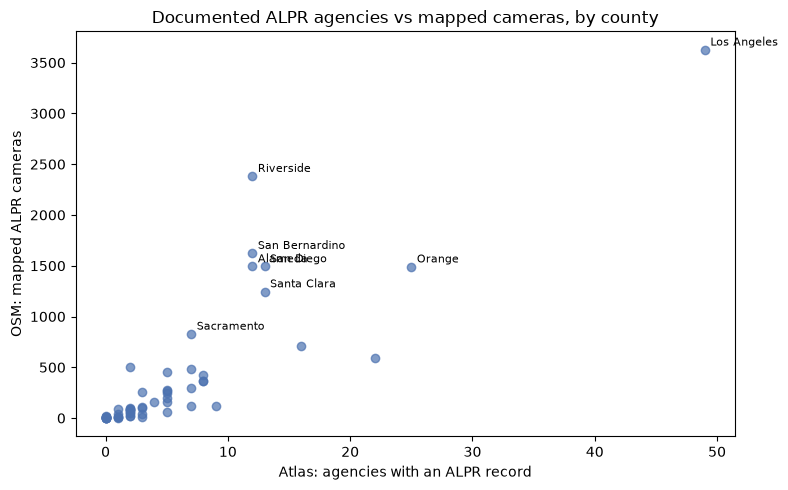

Correlation: 0.87


In [63]:
# chart 1: Atlas ALPR agencies vs mapped cameras, one dot per county
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(county_master['atlas_alpr_agencies'], county_master['cameras'],
           alpha=0.7, color='#4C72B0')

# label the 8 counties with the most cameras
for name, row in county_master.head(8).iterrows():
    ax.annotate(name.replace(' County', ''),
                (row['atlas_alpr_agencies'], row['cameras']),
                fontsize=8, xytext=(4, 3), textcoords='offset points')

ax.set_xlabel('Atlas: agencies with an ALPR record')
ax.set_ylabel('OSM: mapped ALPR cameras')
ax.set_title('Documented ALPR agencies vs mapped cameras, by county')
plt.tight_layout()
plt.show()

r = county_master['atlas_alpr_agencies'].corr(county_master['cameras'])
print(f'Correlation: {r:.2f}')

- scatter of 58 dots, with most bunched near bottom left, small counties with few of either 
- los angeles way out on right (49 agencies, 3,627 cameras)
- san fran is low on x-axis(only2 agencies) but with 501 cameras 
- riverside high up (2,383 cameras( with only 12 agencies)

- correlation probably somewhere around 0.6 to 0.8, related but far from perfect match. 

In [64]:
no_la = county_master.drop('Los Angeles County')
print(f"Without LA: {no_la['atlas_alpr_agencies'].corr(no_la['cameras']):.2f}")

Without LA: 0.76


- riverside is clear outlier, 2,383 cameras with only 12 atlas agencies, far above the trend 
- san fran is the unlabeled dot near (2,500), 
- for accountability project, (these gaps are the interesting part), cameras are on the street, but the public paper trail is thin
- some possible reasons , nobody has filed public records requests there yet, cameras run by private businesses or HOAs that never show up in agency records or simply active volunteer mappers. 

In [65]:
 # documentation gap: where do the two sources disagree?
cols = ['cameras', 'cameras_flock', 'atlas_alpr_agencies', 'atlas_deployments']

print('Mapped cameras but NO Atlas ALPR record:')
display(county_master[(county_master['cameras'] > 0) &
                      (county_master['atlas_alpr_agencies'] == 0)][cols])

print('Atlas ALPR record but NO mapped cameras:')
display(county_master[(county_master['cameras'] == 0) &
                      (county_master['atlas_alpr_agencies'] > 0)][cols])

Mapped cameras but NO Atlas ALPR record:


,cameras,cameras_flock,atlas_alpr_agencies,atlas_deployments
county_name,,,,
Mariposa County,19,16,0,0
Tuolumne County,15,15,0,2
Amador County,14,12,0,0
Del Norte County,11,10,0,1
Trinity County,7,4,0,0
Inyo County,3,0,0,0
Siskiyou County,1,1,0,2


Atlas ALPR record but NO mapped cameras:


,cameras,cameras_flock,atlas_alpr_agencies,atlas_deployments
county_name,,,,


- Table1, 7 counties with mapped cameras but no Atlas ALPR record. All rural, like  sierra foothills (mariposa, tuolumne, amador), North Coast - Del Norte, Trinity, Siskiyou, which are Humboldt's neighbors. 
- table 2 empty, (every county where atlas documents ALPR use also has mapped cameras. gap only goes one way , mapping is ahead of the public records, not the other way around)

In [66]:
# who runs and operates these 70 cameras
# gap counties?
gap = county_master[(county_master['cameras'] > 0) &
                    (county_master['atlas_alpr_agencies'] == 0)].index

gap_cams = cams_loc[cams_loc['county_name'].isin(gap)]
print(len(gap_cams), 'cameras in', len(gap), 'gap counties')

(gap_cams.groupby(['county_name', 'city', 'operator_clean'], dropna=False)
         .size()
         .rename('cameras')
         .reset_index()
         .sort_values(['county_name', 'cameras'], ascending=[True, False]))

70 cameras in 7 gap counties


,county_name,city,operator_clean,cameras
2,Amador County,Martell,Lowe's,3
3,Amador County,Martell,NaN,3
5,Amador County,Plymouth,NaN,3
0,Amador County,Camanche North Shore,NaN,1
1,Amador County,Drytown,NaN,1
4,Amador County,Pine Grove,NaN,1
6,Amador County,Sutter Creek,NaN,1
7,Amador County,NaN,NaN,1
10,Del Norte County,NaN,NaN,8
9,Del Norte County,Crescent City,NaN,2


# Big box store cameras (home depot and lowe's)

# Many cameras are operated by Lowe's and Home Depot, I want to understand these connections, we can highlight to better understand this. 

- The store's Flock data can reach police. Public records the EFF obtained showed a Texas sheriff's office could search Flock license plate readers at 173 Lowe's locations across the US, plus cameras at dozens of Home Depot stores (https://www.404media.co/home-depot-and-lowes-share-data-from-hundreds-of-ai-cameras-with-cops/). Flock says privately run cameras have more limited sharing settings, but the stores set those, not the shoppers. 

- California lawsuit, it april 2026, five California residents sued Home Depot in Sacramento County Superior Court (Schmierer v. Home Depot). They allege Flock ALPRs are installed at all 233 California Home Depot stores, that the privacy policy is missing things California's ALPR law requires (no retention period, no limits on sharing with federal or immigration agencies), and that agencies like ICE can access the data. Home Depot says it doesn't share plate data with federal law enforcement. These are allegations, and the case is early (https://stateofsurveillance.org/news/home-depot-alpr-flock-safety-parking-lot-surveillance-class-action-2026/)

- Shareholders asked for transparency. In May 2026, both companies' boards recommended voting against shareholder proposals asking for reports on customer privacy risks. Advocates connect this to immigration enforcement at stores where day laborers gather. (https://prospect.org/2026/05/21/home-depot-lowes-downplay-customer-surveillance-threats-flock-cameras-immigration/)

- Lawmakers in other states are pushing too, In conneticut, legislators demanded answers from both HomeDepot and Lowes about their cameras and data sharing (https://www.wfsb.com/2026/05/26/ct-lawmakers-demanding-answers-home-depot-lowes-license-plate-cameras-data-sharing/)

# Why does this matter??
- Business rules / "A camera can be operated by law enforcement agency or private business" - this gives us a good reason for an operator superclass with agency and business subtypes for ERD. 

- Scenario question 2 ("Who queried my data") gets difficult when a privarte store owns the camera but police are able to search it.

- one caveat for numbers - 248 home depot cameras are only the ones volunteers tagged as Home Depot. If lawsuit is right about 233 stores, with several cameras per lot, real number might be higher. Which probably sit in that 77% unknown operator group.

In [67]:
#big box retailers running ALPR cameras 
RETAILERS = {
    'home depot': 'Home Depot',
    "lowe's":     "Lowe's",
    'lowe’s':     "Lowe's",       # curly apostrophe version
    'walmart':    'Walmart',
    "sam's club": "Sam's Club",
    'target':     'Target',
}

def retailer(op):
    if pd.isna(op):
        return pd.NA
    o = op.lower()
    for key, name in RETAILERS.items():
        if key in o:
            return name
    return pd.NA

cams_loc['retailer'] = cams_loc['operator_clean'].apply(retailer)
retail = cams_loc[cams_loc['retailer'].notna()]

print(len(retail), 'cameras run by big-box retailers')
retail.groupby('retailer').agg(
    cameras=('osm_id', 'size'),
    cities=('city', 'nunique'),
    counties=('county_name', 'nunique'),
).sort_values('cameras', ascending=False)

463 cameras run by big-box retailers


,cameras,cities,counties
retailer,,,
Home Depot,248,77,23
Lowe's,164,57,29
Walmart,34,2,1
Sam's Club,13,1,1
Target,4,2,2


- home depot - 248 cameras in 77 cities, lawsuit alleges 233 california stores. Cities arent the same as stores ( bigger cities might have several), but suggests volunteers have tagged maybe a third of home depots camera locations at most 
- walmart 34 cameras in just 2 cities,(very concentrated) It could be one or two stores with lost of cameras, or one active mapper who tagged a couple of locations carefully. - worth closer look

In [68]:
# connect store cameras to the Atlas: do police in the same city use Flock ALPR?
flock_police_cities = set(atlas.loc[is_flock_alpr, 'city'].dropna())
print(len(flock_police_cities), 'cities where the Atlas documents Flock ALPR use')

retail = retail.assign(
    police_flock_same_city=retail['city'].isin(flock_police_cities)
)

summary = retail.groupby('retailer').agg(
    cameras=('osm_id', 'size'),
    in_flock_police_city=('police_flock_same_city', 'sum'),
)
summary['share_%'] = (summary['in_flock_police_city'] / summary['cameras'] * 100).round(1)
summary.sort_values('cameras', ascending=False)

180 cities where the Atlas documents Flock ALPR use


,cameras,in_flock_police_city,share_%
retailer,,,
Home Depot,248,97,39.1
Lowe's,164,75,45.7
Walmart,34,0,0.0
Sam's Club,13,0,0.0
Target,4,2,50.0


- for each chain, how many of its cameras are in a city where the Atlas documents police Flock use, and what percent that is. Expect a good share, maybe a third to to half or more, since Flock is common in the same suburbs where these stores are.

- a store camera in the same city as police Flock cameras mean both are on the same platform in the same area. it doesn't prove that particular store shares its data with those police. sharing depends on settings we might not be able to see. The reporting shows that sharing does happen in some places, so this table shows where it could happen./ more accurate 

Each city where store cameras and documented police Flock use overlap, and which police agencies are involved. 

In [69]:
# highlight table: cities with store cameras AND documented police Flock use
police = (atlas[is_flock_alpr]
          .groupby('city')['agency_name']
          .agg(lambda s: '; '.join(sorted(s.unique())))
          .rename('police_flock_agencies'))

store_city = pd.crosstab([retail['city'], retail['county_name']], retail['retailer'])
store_city['store_cams'] = store_city.sum(axis=1)
store_city = store_city.reset_index()

overlap = (store_city
           .merge(police, left_on='city', right_index=True, how='inner')
           .sort_values('store_cams', ascending=False))

print(len(overlap), 'cities with both store cameras and police Flock use')
overlap.head(20)

55 cities with both store cameras and police Flock use


,city,county_name,Home Depot,Lowe's,Sam's Club,Target,Walmart,store_cams,police_flock_agencies
102,Stockton,San Joaquin County,6,8,0,0,0,14,Stockton Police Department
86,San Diego,San Diego County,8,6,0,0,0,14,San Diego Police Department
82,Sacramento,Sacramento County,9,0,0,0,0,9,California Highway Patrol
81,Roseville,Placer County,7,1,0,0,0,8,Roseville Police Department
55,Lodi,San Joaquin County,3,4,0,0,0,7,Lodi Police Department
27,El Centro,Imperial County,3,3,0,0,0,6,El Centro Police Department; Imperial County S...
88,San Fernando,Los Angeles County,5,0,0,0,0,5,San Fernando Police Department
78,Redlands,San Bernardino County,0,5,0,0,0,5,Redlands Police Department
69,Ontario,San Bernardino County,0,5,0,0,0,5,Ontario Police Department
17,Citrus Heights,Sacramento County,0,4,0,0,0,4,Citrus Heights Police Department


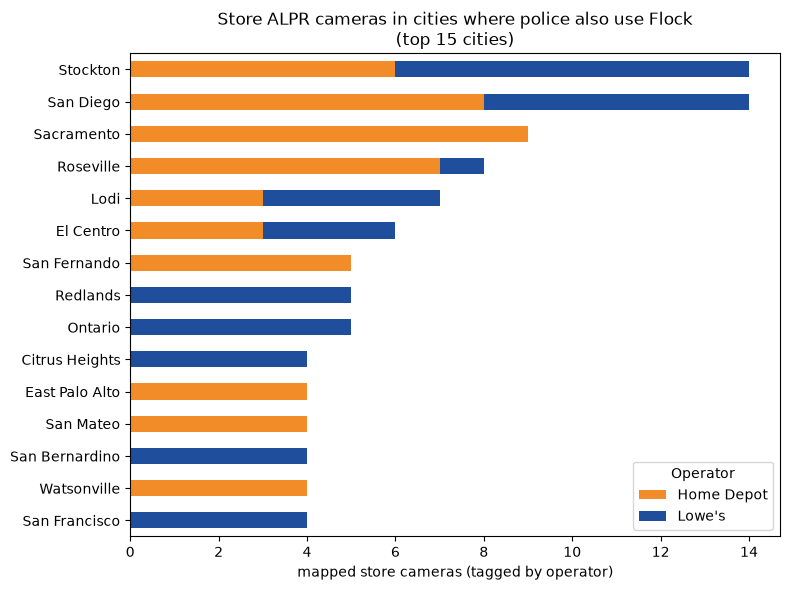

In [70]:
# chart: top 15 cities with store cameras + police Flock use
top = overlap.head(15).set_index('city')[['Home Depot', "Lowe's"]].iloc[::-1]

ax = top.plot.barh(stacked=True, figsize=(8, 6), color=['#F28C28', '#1F4E9C'])
ax.set_title('Store ALPR cameras in cities where police also use Flock\n(top 15 cities)')
ax.set_xlabel('mapped store cameras (tagged by operator)')
ax.set_ylabel('')
ax.legend(title='Operator')
plt.tight_layout()
plt.show()

# Immigration search records: from 1612 to 21

In [71]:
# police flock searches with immigration related reasons - public records audit logs
imm_raw = pd.read_csv('data/raw/immigration-records-2026-10-16.csv', low_memory=False)
print(imm_raw.shape, '<- all states')

# privacy, drop officer names before doing anything else
imm = imm_raw.drop(columns=['name', 'best_name', 'best_name_confidence'])

# California only
imm_ca = imm[imm['org_state'] == 'CA'].copy()
print(len(imm_ca), 'California searches by', imm_ca['org_name'].nunique(), 'organizations')

imm_ca[['search_time_utc', 'org_name', 'org_locality', 'reason',
        'search_type', 'total_devices_searched']].head()

(27501, 25) <- all states
1612 California searches by 27 organizations


,search_time_utc,org_name,org_locality,reason,search_type,total_devices_searched
7,2024-12-28T10:50:14.000Z,Palm Springs CA PD,Palm Springs,2412d-3366 10851 dhs,lookup,0.0
10,2024-12-28T10:51:04.000Z,Palm Springs CA PD,Palm Springs,2412d-3366 10851 dhs,lookup,0.0
11,2024-12-28T10:51:34.000Z,Palm Springs CA PD,Palm Springs,2412d-3366 10851 dhs,lookup,0.0
12,2024-12-28T10:51:54.000Z,Palm Springs CA PD,Palm Springs,2412d-3366 10851 dhs,lookup,0.0
13,2024-12-28T10:52:33.000Z,Palm Springs CA PD,Palm Springs,2412d-3366 10851 dhs,lookup,0.0


In [72]:
import glob
glob.glob('**/*immigration*', recursive=True)

['data/tables/ca_immigration_searches_labeled.csv',
 'data/raw/immigration-records-2026-10-16.csv']

In [73]:
import os, glob
hits = [p for p in glob.glob(os.path.expanduser('~/**/*.csv'), recursive=True)
        if 'immig' in p.lower() or 'profil' in p.lower()]
hits

['/home/jovyan/CS 325 DEFLOCK Project/data/tables/ca_immigration_searches_labeled.csv',
 '/home/jovyan/CS 325 DEFLOCK Project/data/raw/immigration-records-2026-10-16.csv']

In [74]:
# move the raw file into data/raw (creates the folder if it doesn't exist)
#os.makedirs('data/raw', exist_ok=True)
#os.rename('immigration-records-2026-10-16.csv',
          #'data/raw/immigration-records-2026-10-16.csv')
#print(os.listdir('data/raw'))

# Immigration Records

In [75]:
# who ran california searches
by_org = (imm_ca.groupby('org_name')
          .agg(searches=('id', 'size'),
               first_search=('search_time_utc', 'min'),
               last_search=('search_time_utc', 'max'),
               median_devices=('total_devices_searched', 'median'))
          .sort_values('searches', ascending=False))

by_org['share_%'] = (by_org['searches'] / by_org['searches'].sum() * 100).round(1)
by_org

,searches,first_search,last_search,median_devices,share_%
org_name,,,,,
California Highway Patrol,945,2024-12-23T18:27:00.000Z,2025-07-26T00:39:11.000Z,14693.0,58.6
Palm Springs CA PD,143,2024-07-13T05:28:02.000Z,2024-12-28T14:11:01.000Z,0.0,8.9
San Diego County CA SD,135,2024-09-27T17:16:31.000Z,2025-05-28T16:59:37.000Z,9491.0,8.4
Los Angeles County CA SD,61,2025-04-22T18:08:28.000Z,2025-09-09T23:03:54.000Z,14914.0,3.8
Riverside County CA District Attorney,60,2024-07-18T06:49:39.000Z,2025-12-29T20:56:08.000Z,52290.0,3.7
Riverside County CA SO,52,2024-01-26T21:15:24.000Z,2025-07-22T16:26:59.000Z,5370.0,3.2
Monterey County CA SO,42,2025-02-17T16:10:51.000Z,2025-05-14T01:44:09.000Z,14339.0,2.6
Beaumont CA PD,42,2024-07-13T05:04:11.000Z,2025-04-18T07:50:19.000Z,362.0,2.6
El Cajon CA PD,27,2024-06-04T22:38:44.000Z,2025-12-08T23:13:29.000Z,24179.0,1.7


- CHP has ran 945 searches in 7 months (Dec 2024 - Jul 2025),each covering about 14,700 cameras. Biggest pattern in file.
- riverside county district attorney's searches are the widest with a median of 52,290 cameras per search, more than 3 times the others
- bust activity : bakersfield pd ran 22 searches in about 20 minutes on march 27th 2025 and anaheim pd ran 14 in 40 minutes on jun 12, 2025. Bursts like that usually mean one case or operation, not 22 separate investigations. 
- NCRIC (Northern California Regional Intelligence Center, a fusion center where local, state, and federal agencies share intelligence. ( worth knowing fusion centers are a common route for data to reach federal agencies.
- top california reasons earlier were stonegarden entries
- operation stonegarden is a department of homeland security grant that pays state and local agencies for border related enforcement, CHP may be running searches under that program. 

In [76]:
import re

def reason_group(r):
    r = str(r).lower()
    if re.search(r'\b(ice|ero|deport\w*|immigra\w*|usbp|border patrol)\b', r):
        return 'explicit immigration'
    if 'stonegarden' in r:
        return 'Stonegarden (DHS grant)'
    if re.search(r'\b(dhs|hsi|cbp)\b', r):
        return 'DHS / CBP mention'
    return 'other keyword match'

imm_ca['reason_group'] = imm_ca['reason'].apply(reason_group)

display(imm_ca['reason_group'].value_counts())

top_orgs = by_org.head(8).index
pd.crosstab(imm_ca.loc[imm_ca['org_name'].isin(top_orgs), 'org_name'],
            imm_ca['reason_group'])

reason_group
Stonegarden (DHS grant)    1018
DHS / CBP mention           439
other keyword match          91
explicit immigration         64
Name: count, dtype: int64

reason_group,DHS / CBP mention,Stonegarden (DHS grant),explicit immigration,other keyword match
org_name,,,,
Beaumont CA PD,42,0,0,0
California Highway Patrol,0,942,3,0
Los Angeles County CA SD,0,0,0,61
Monterey County CA SO,0,42,0,0
Palm Springs CA PD,143,0,0,0
Riverside County CA District Attorney,60,0,0,0
Riverside County CA SO,47,0,4,1
San Diego County CA SD,124,7,0,4


- CHP 942 of 945 searches are Stonegarden, so CHP's big number comes from DHS funded Operation Stonegarden program,not from searches that name ICE directly. Only 3 CHP searches mention immigration directly 
- Only 64 searches statewide about 4% explicitly say ICE, ERO, Deportation or immigration. Thats the most direct evidence in this file, and its much smaller, sharper number than 1,612 immigration searches.
- Palm Springs, the San Diego County sheriff, the Riverside DA, and Beaumont are almost entirely DHS/CBP mention, like the vehicle theft case. THose might be joint cases with Homeland Security Investigations which also handles smuggling and trafficking. 
- LA county sheriff, all 61 are other keyword match, none of patterns matched.
- “ICE” in a reason means the search was tied to immigration enforcement. “Stonegarden” means the agency was working under a DHS grant for border-area operations, which can include drug interdiction and smuggling, not only immigration. If your write-up said “CHP ran 945 immigration searches,” that would overstate what the data shows. An accurate version: “CHP ran 942 searches logged under Operation Stonegarden, a DHS-funded program; 3 explicitly referenced immigration.” Precise wording like that makes your findings much harder to dismiss.

In [77]:
#real reason text for the two groups ,,we can't judge from counts alone
for group in ['explicit immigration', 'other keyword match']:
    print(f'\n=== {group} ===')
    display(imm_ca.loc[imm_ca['reason_group'] == group, ['org_name', 'reason']]
                  .value_counts()
                  .head(15))


=== explicit immigration ===


org_name                     reason                                       
Bakersfield CA PD            AC req Home Deport GTA                           22
Anaheim CA PD                ICE                                              14
Escondido CA PD              Immigration Protest                               6
San Mateo CA PD              Home Deport ORC                                   4
Riverside County CA SO       ICE SW 062925                                     4
San Bernardino County CA SO  got ice                                           3
Menifee CA PD                Immigration fraud                                 3
California Highway Patrol    ICE case                                          3
Irvine CA PD                 Anaheim PD ICE Impersonation series June 2024     2
San Bernardino County CA SO  ICE PROTEST                                       2
Irvine CA PD                 anaheim pd ICE impersonation case                 1
Name: count, dtype: int64


=== other keyword match ===


org_name                     reason                            
Los Angeles County CA SD     Guardian Invest                       35
                             Guardian Case                         10
NCRIC                        ATL Guardian Subject                   7
Los Angeles County CA SD     guardian Invest                        7
                             Guardian Invest.                       4
San Diego County CA SD       OFFICER SAFETY / THREATS TO AGENTS     4
San Bernardino County CA SO  poss involved                          3
Los Angeles County CA SD     guardian invest                        3
San Francisco CA PD          FBI Guardian Lead                      2
Menifee CA PD                AMBER ALERT                            2
Los Angeles County CA SD     Guardian Inves                         2
Orange County SO CA          Guardian                               2
Riverside County CA SO       FBI guardian                           1
NCRIC                     

- AC req Home Deport GTA (Bakersfield, 22)	A typo for “Home Depot.” GTA = grand theft auto. It’s a vehicle theft at Home Depot, which also explains the 22-search burst
                                                                        
- Home Deport ORC (San Mateo, 4)	Same typo. ORC = organized retail crime at Home Depot. This ties back to your store-camera work.

- Immigration Protest (6), ICE PROTEST (2)	Searches connected to protests. That’s a different but serious issue: ALPR use around protest activity.

-ICE Impersonation (Irvine, 3)	Investigating someone pretending to be ICE, a crime against the public

- Immigration fraud (Menifee, 3)	A fraud crime, likely scams that target immigrants

-got ice (San Bernardino, 3)	Unclear. “Ice” is also slang for meth.

- ICE (Anaheim, 14), ICE SW 062925 (Riverside SO, 4), ICE case (CHP, 3)	These are the ones that plausibly point to immigration enforcement. “SW” likely means search warrant, dated 06/29/25.

In [78]:
# hand-coded labels for the 'explicit immigration' group (judgment calls -> cleaning log)
def refine(r):
    r = str(r).lower()
    if 'home deport' in r:
        return 'typo: Home Depot theft'
    if 'protest' in r:
        return 'protest-related'
    if 'imperson' in r:
        return 'ICE impersonation (crime)'
    if 'fraud' in r:
        return 'immigration fraud (crime)'
    if 'got ice' in r:
        return 'unclear'
    return 'enforcement-related'

explicit = imm_ca[imm_ca['reason_group'] == 'explicit immigration'].copy()
explicit['refined'] = explicit['reason'].apply(refine)

pd.crosstab(explicit['org_name'], explicit['refined'], margins=True)

refined,ICE impersonation (crime),enforcement-related,immigration fraud (crime),protest-related,typo: Home Depot theft,unclear,All
org_name,,,,,,,
Anaheim CA PD,0,14,0,0,0,0,14
Bakersfield CA PD,0,0,0,0,22,0,22
California Highway Patrol,0,3,0,0,0,0,3
Escondido CA PD,0,0,0,6,0,0,6
Irvine CA PD,3,0,0,0,0,0,3
Menifee CA PD,0,0,3,0,0,0,3
Riverside County CA SO,0,4,0,0,0,0,4
San Bernardino County CA SO,0,0,0,2,0,3,5
San Mateo CA PD,0,0,0,0,4,0,4


In [79]:
#funnel from keyword matches to plausible enforcement searches
funnel = pd.Series({
    '1. CA searches in the "immigration" file':          len(imm_ca),
    '2. reason names ICE / ERO / immigration / deport':  len(explicit),
    '3. after reading: plausibly enforcement-related':   (explicit['refined'] == 'enforcement-related').sum(),
    '   (separately) protest-related':                   (explicit['refined'] == 'protest-related').sum(),
}, name='searches').to_frame()
display(funnel)

# save the labeled California table (officer names were already dropped in Cell 25)
imm_ca['refined'] = imm_ca['reason_group']                       # start with the broad group
imm_ca.loc[explicit.index, 'refined'] = explicit['refined']      # overwrite the 64 hand-coded rows

imm_ca.to_csv(f'{TABLES}/ca_immigration_searches_labeled.csv', index=False)
print('Saved', len(imm_ca), 'rows to ca_immigration_searches_labeled.csv')
imm_ca['refined'].value_counts()

,searches
"1. CA searches in the ""immigration"" file",1612
2. reason names ICE / ERO / immigration / deport,64
3. after reading: plausibly enforcement-related,21
(separately) protest-related,8


Saved 1612 rows to ca_immigration_searches_labeled.csv


refined
Stonegarden (DHS grant)      1018
DHS / CBP mention             439
other keyword match            91
typo: Home Depot theft         26
enforcement-related            21
protest-related                 8
unclear                         3
immigration fraud (crime)       3
ICE impersonation (crime)       3
Name: count, dtype: int64

- Theimmigration dataset lists 1,612 California Flock searches with immigration-related reasons. After reading the reasons, most turned out to be other things, 1,018 were logged under Operation Stonegarden, a DHS-funded program (942 of them by CHP). 439 only mention DHS or CBP. 91 were unrelated keyword matches, and 26 were Home Depot theft cases hidden behind the typo “Home Deport.” Only 21 searches plausibly relate to immigration enforcement (Anaheim PD, Riverside County Sheriff, CHP), and 8 were connected to protests. The headline number is mostly noise


In [80]:
# city -> county lookup, built from the camera table you already have
city_to_county = (cams_loc.dropna(subset=['city'])
                  .groupby('city')['county_name']
                  .agg(lambda s: s.mode()[0]))

def locality_to_county(loc):
    if pd.isna(loc):
        return pd.NA
    if loc.endswith('County'):
        return loc                          # already a county
    return city_to_county.get(loc, pd.NA)   # look the city up

imm_ca['county_name'] = imm_ca['org_locality'].apply(locality_to_county)

print(imm_ca['county_name'].notna().sum(), 'searches placed in a county')
imm_ca.loc[imm_ca['county_name'].isna(), ['org_name', 'org_locality']].value_counts(dropna=False)

667 searches placed in a county


org_name                   org_locality
California Highway Patrol  NaN             945
Name: count, dtype: int64

# County Findings 

In [81]:
# 1. searches per county, by label
SEARCH_COLS = {
    'enforcement-related':     'search_enforcement',
    'protest-related':         'search_protest',
    'Stonegarden (DHS grant)': 'search_stonegarden',
    'DHS / CBP mention':       'search_dhs_cbp',
}
searches = (pd.crosstab(imm_ca['county_name'], imm_ca['refined'])
              .reindex(columns=SEARCH_COLS.keys(), fill_value=0)
              .rename(columns=SEARCH_COLS))

# 2. big-box store cameras per county
stores = pd.crosstab(retail['county_name'], retail['retailer'])
stores.columns = ['store_' + c.lower().replace("'", '').replace(' ', '_') for c in stores.columns]
stores['store_cams_total'] = stores.sum(axis=1)

# 3. join everything onto the county master
county_findings = (county_master
                   .join(stores, how='left')
                   .join(searches, how='left')
                   .fillna(0))

new_cols = list(stores.columns) + list(searches.columns)
county_findings[new_cols] = county_findings[new_cols].astype(int)

assert len(county_findings) == 58
print('County findings:', county_findings.shape)
county_findings.head(10)

County findings: (58, 28)


,land_sq_mi,atlas_deployments,atlas_agencies,atlas_tech_types,atlas_alpr_agencies,atlas_flock_alpr_agencies,cameras,cameras_flock,cams_hoa,cams_gov,...,store_home_depot,store_lowes,store_sams_club,store_target,store_walmart,store_cams_total,search_enforcement,search_protest,search_stonegarden,search_dhs_cbp
county_name,,,,,,,,,,,,,,,,,,,,,
Los Angeles County,4060.2,203,72,12,49,25,3627,2516,10,149,...,82,23,13,2,34,154,0,0,0,0
Riverside County,7209.3,51,18,7,12,10,2383,2063,0,0,...,11,11,0,0,0,22,4,0,0,303
San Bernardino County,20068.2,37,14,10,12,5,1624,980,0,0,...,18,31,0,0,0,49,0,2,0,0
San Diego County,4210.5,65,26,9,13,6,1493,708,1,17,...,18,10,0,0,0,28,0,6,34,124
Alameda County,737.5,56,21,10,12,10,1493,1341,8,48,...,5,2,0,0,0,7,0,0,0,0
Orange County,792.9,70,28,10,25,12,1491,1137,0,16,...,15,3,0,2,0,20,14,0,0,7
Santa Clara County,1291.1,45,22,8,13,11,1246,1074,0,0,...,2,0,0,0,0,2,0,0,0,5
Sacramento County,965.3,31,13,11,7,4,829,649,0,0,...,24,15,0,0,0,39,0,0,0,0
San Mateo County,448.6,31,19,7,16,13,708,560,2,0,...,8,0,0,0,0,8,0,0,0,0


In [82]:
# headline view: the columns that tell the story, with readable names
HEADLINE = {
    'cameras':                   'Mapped ALPR cameras',
    'flock_share_%':             'Flock %',
    'cams_per_100_sq_mi':        'Cameras per 100 sq mi',
    'atlas_alpr_agencies':       'Atlas: ALPR agencies',
    'cams_law':                  'Police-run cameras',
    'store_cams_total':          'Big-box store cameras',
    'search_enforcement':        'Immigration-enforcement searches',
    'search_protest':            'Protest-related searches',
    'search_stonegarden':        'Stonegarden searches',
}
headline = (county_findings[list(HEADLINE)]
            .rename(columns=HEADLINE)
            .sort_values('Mapped ALPR cameras', ascending=False))

# save both versions
county_findings.reset_index().to_csv(f'{TABLES}/county_findings_full.csv', index=False)
headline.reset_index().to_csv(f'{TABLES}/county_findings_headline.csv', index=False)

chp = (imm_ca['org_name'] == 'California Highway Patrol').sum()
print(f'Not in table: {chp} statewide CHP searches (no county)')
headline.head(15)

Not in table: 945 statewide CHP searches (no county)


,Mapped ALPR cameras,Flock %,Cameras per 100 sq mi,Atlas: ALPR agencies,Police-run cameras,Big-box store cameras,Immigration-enforcement searches,Protest-related searches,Stonegarden searches
county_name,,,,,,,,,
Los Angeles County,3627,69.4,89.3,49,238,154,0,0,0
Riverside County,2383,86.6,33.1,12,38,22,4,0,0
San Bernardino County,1624,60.3,8.1,12,99,49,0,2,0
San Diego County,1493,47.4,35.5,13,661,28,0,6,34
Alameda County,1493,89.8,202.4,12,573,7,0,0,0
Orange County,1491,76.3,188.0,25,339,20,14,0,0
Santa Clara County,1246,86.2,96.5,13,104,2,0,0,0
Sacramento County,829,78.3,85.9,7,102,39,0,0,0
San Mateo County,708,79.1,157.8,16,166,8,0,0,0
